# Demand Tier Prediction from Real Covers

**Thesis argument:** Demand is not random. It is driven by a combination of observable signals including weather, day of week, season, hotel occupancy, and special occasions. This notebook builds a model that learns those relationships from 294 days of actual observed dinner covers, then uses that knowledge to generate synthetic training data at scale.

**Label:** actual afternoon cover count, bucketed into LOW / MEDIUM / HIGH using tertiles from real observations

**Features:** contextual signals that are observable before the shift begins

**Pipeline:** real covers + occupancy + weather + calendar signals → regression → synthetic data → classifier → tier → CP-SAT scheduling

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from pathlib import Path

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)

DATA_RAW  = Path('../data/raw')
DATA_PREP = Path('../data_prep/outputs')
FIG_DIR   = Path('../thesis/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load Data

We load two datasets and join them on date.

The **covers data** is the ground truth label source. It contains the actual number of dinner guests served on 294 real days at the restaurant. This is what we are trying to predict.

The **occupancy data** is the feature source. It contains daily hotel context (how full the hotel was, arrivals, departures) enriched with real temperatures from the Open-Meteo historical archive and Hungarian public holidays. These are the signals the thesis is trying to prove drives demand.

In [ ]:
# Real dinner covers; our ground truth label
covers = pd.read_csv(DATA_RAW / 'covers_data.csv', parse_dates=['date'])
covers = covers[covers['afternoon_covers'].notna() & (covers['afternoon_covers'] != '')].copy()
covers['afternoon_covers'] = pd.to_numeric(covers['afternoon_covers'])
print(f"Covers: {len(covers)} days  |  {covers['date'].min().date()} to {covers['date'].max().date()}")
print(f"Cover count stats:\n{covers['afternoon_covers'].describe().round(1)}")

Covers: 294 days  |  2025-01-10 to 2026-04-06
Cover count stats:
count    294.0
mean     249.4
std      116.7
min       23.0
25%      158.2
50%      238.0
75%      341.0
max      545.0
Name: afternoon_covers, dtype: float64


In [49]:
# Enriched occupancy -- real hotel context + real weather + holidays
occupancy = pd.read_csv(DATA_PREP / 'occupancy_enriched.csv', parse_dates=['date'])
print(f"Occupancy: {len(occupancy)} days  |  {occupancy['date'].min().date()} to {occupancy['date'].max().date()}")
occupancy.head()

Occupancy: 1008 days  |  2023-07-10 to 2026-04-12


,date,occupancy_%,day_of_week,day_name,is_weekend,season,special_day_name,is_special_day,temp_max,temp_min,temp_mean
0,2023-07-10,22.52,0,Monday,0,Summer,NaN,0,33.8,18.5,26.9
1,2023-07-11,24.50,1,Tuesday,0,Summer,NaN,0,31.0,19.8,26.0
2,2023-07-12,25.83,2,Wednesday,0,Summer,NaN,0,32.3,19.4,25.4
3,2023-07-13,23.18,3,Thursday,0,Summer,NaN,0,29.3,19.8,24.3
4,2023-07-14,15.23,4,Friday,0,Summer,NaN,0,27.5,18.9,23.7


## 2. Build the Feature Table

We join the covers (label) with the occupancy data (features) on date. Only days where both are available are kept. This gives us 294 complete observations where we know both what the signals looked like and what actually happened.

In [50]:
df = covers.merge(occupancy, on='date', how='inner')
print(f"Merged: {len(df)} days with both covers and occupancy context")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
df.head()

Merged: 294 days with both covers and occupancy context
Date range: 2025-01-10 to 2026-04-06


,date,afternoon_covers,occupancy_%,day_of_week,day_name,is_weekend,season,special_day_name,is_special_day,temp_max,temp_min,temp_mean
0,2025-01-10,124.0,19.21,4,Friday,0,Winter,NaN,0,9.5,-0.3,3.8
1,2025-01-22,117.0,29.80,2,Wednesday,0,Winter,NaN,0,0.6,-1.3,-0.7
2,2025-03-03,179.0,71.52,0,Monday,0,Spring,NaN,0,9.1,-1.4,3.3
3,2025-03-27,308.0,50.99,3,Thursday,0,Spring,NaN,0,17.6,8.6,12.3
4,2025-04-27,149.0,31.79,6,Sunday,1,Spring,NaN,0,18.8,7.0,12.8


## 3. Create the Label

We bucket actual cover counts into LOW / MEDIUM / HIGH demand tiers using tertile thresholds computed from the real distribution. This means the tier boundaries are set by what actually happened at this restaurant, not by an external rule.

Tertile bucketing gives us roughly equal class sizes, which is important for model training.

In [51]:
low_thresh  = df['afternoon_covers'].quantile(0.33)
high_thresh = df['afternoon_covers'].quantile(0.67)

print(f"Tier thresholds (from actual covers):")
print(f"  LOW    : up to {low_thresh:.0f} covers")
print(f"  MEDIUM : {low_thresh:.0f} to {high_thresh:.0f} covers")
print(f"  HIGH   : above {high_thresh:.0f} covers")

def to_tier(cover_count):
    if cover_count <= low_thresh:
        return 'low'
    elif cover_count <= high_thresh:
        return 'medium'
    return 'high'

df['tier'] = df['afternoon_covers'].apply(to_tier)
print(f"\nTier distribution:")
print(df['tier'].value_counts().sort_index())

Tier thresholds (from actual covers):
  LOW    : up to 182 covers
  MEDIUM : 182 to 305 covers
  HIGH   : above 305 covers

Tier distribution:
tier
high       96
low        97
medium    101
Name: count, dtype: int64


## 4. Exploratory Analysis - Do the Signals Relate to Covers?

Before fitting anything, we look at whether each candidate feature actually has a visible relationship with cover counts. This is an evidence check. If a feature shows no pattern here, it probably will not help the model.

We are looking for features where cover counts visibly shift as the feature changes -- a rising trend in the scatter plots, or boxes at clearly different heights in the box plots.

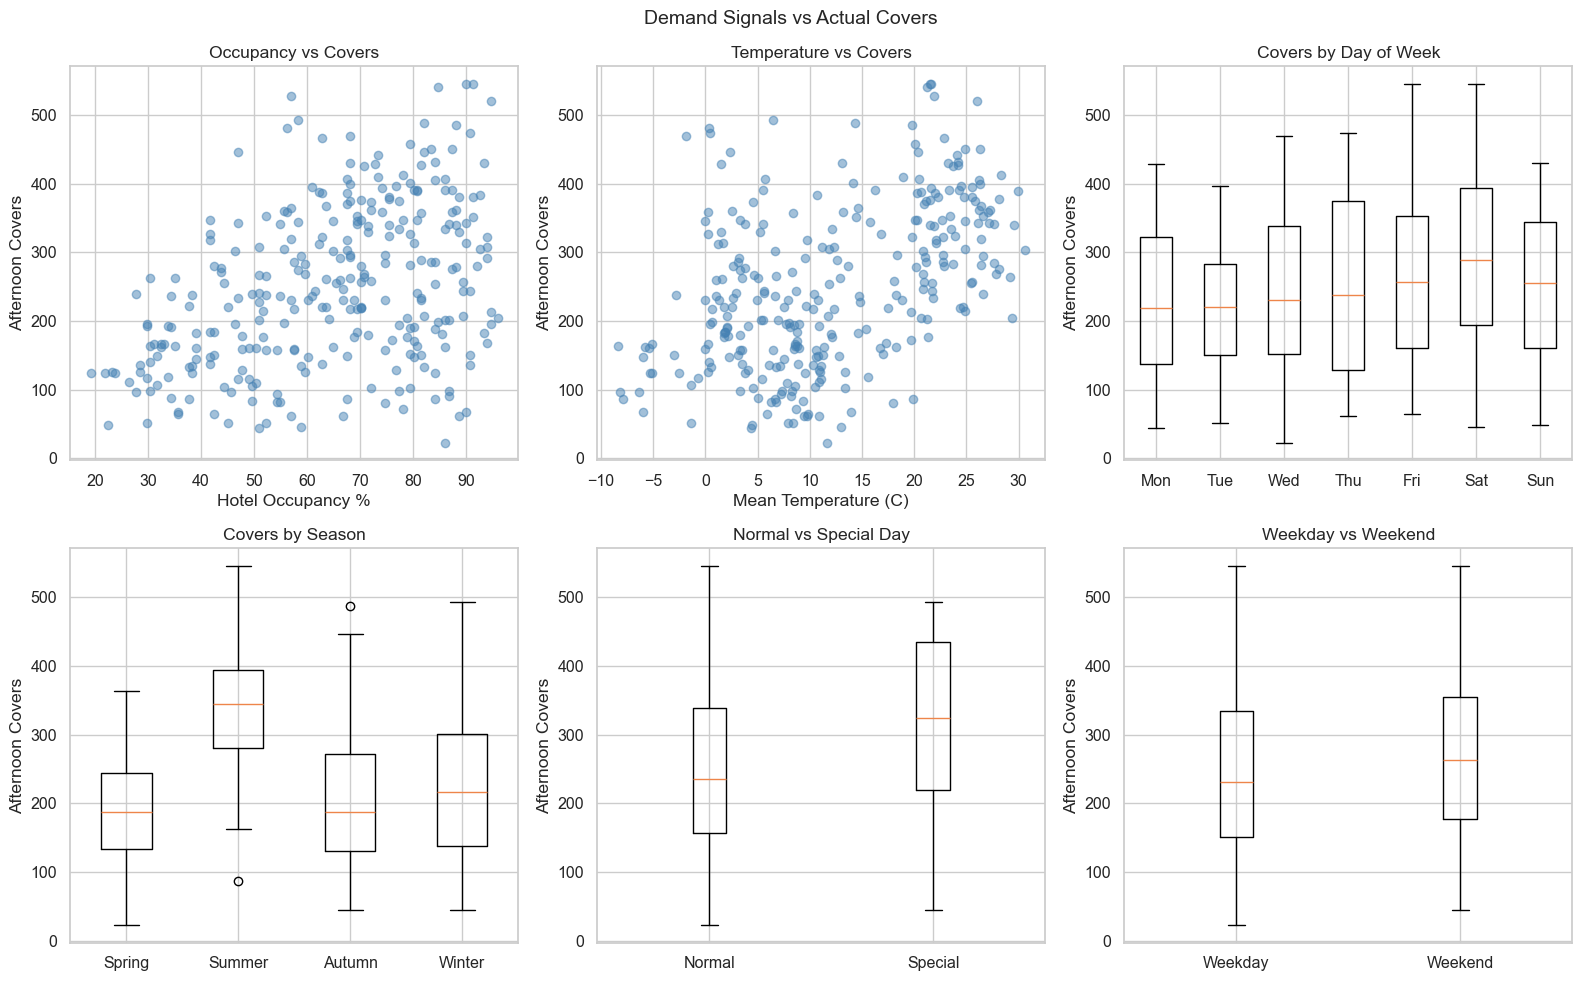

In [52]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0,0].scatter(df['occupancy_%'], df['afternoon_covers'], alpha=0.5, color='steelblue')
axes[0,0].set_xlabel('Hotel Occupancy %')
axes[0,0].set_ylabel('Afternoon Covers')
axes[0,0].set_title('Occupancy vs Covers')

axes[0,1].scatter(df['temp_mean'], df['afternoon_covers'], alpha=0.5, color='steelblue')
axes[0,1].set_xlabel('Mean Temperature (C)')
axes[0,1].set_ylabel('Afternoon Covers')
axes[0,1].set_title('Temperature vs Covers')

axes[0,2].boxplot([df[df['day_of_week']==d]['afternoon_covers'] for d in range(7)],
                  labels=['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
axes[0,2].set_ylabel('Afternoon Covers')
axes[0,2].set_title('Covers by Day of Week')

axes[1,0].boxplot([df[df['season']==s]['afternoon_covers'] for s in ['Spring','Summer','Autumn','Winter']],
                  labels=['Spring','Summer','Autumn','Winter'])
axes[1,0].set_ylabel('Afternoon Covers')
axes[1,0].set_title('Covers by Season')

axes[1,1].boxplot([df[df['is_special_day']==0]['afternoon_covers'],
                   df[df['is_special_day']==1]['afternoon_covers']],
                  labels=['Normal','Special'])
axes[1,1].set_ylabel('Afternoon Covers')
axes[1,1].set_title('Normal vs Special Day')

axes[1,2].boxplot([df[df['is_weekend']==0]['afternoon_covers'],
                   df[df['is_weekend']==1]['afternoon_covers']],
                  labels=['Weekday','Weekend'])
axes[1,2].set_ylabel('Afternoon Covers')
axes[1,2].set_title('Weekday vs Weekend')

plt.suptitle('Demand Signals vs Actual Covers', fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / 'demand_signals_eda.png', dpi=150)
plt.show()

## 5. Regression - Quantifying the Relationship Between Signals and Covers

We fit an Ordinary Least Squares regression to measure how much each signal contributes to cover variation. This serves two purposes:

First, it tells us which signals are statistically significant -- meaning their relationship with covers is unlikely to be random. Any feature with a p-value above 0.05 is dropped.

Second, it gives us the fitted model we will use to generate synthetic data. The regression learns the conditional mean of covers given the signals. The residuals capture the natural noise that the signals do not explain.

Season dummies use Autumn as the baseline. Summer and Winter are measured relative to how quiet Autumn typically is.

In [53]:
# One-hot encode season -- Autumn is the baseline (dropped)
season_dummies = pd.get_dummies(df['season'], prefix='season', drop_first=False)
df = pd.concat([df, season_dummies], axis=1)

# First pass -- include all candidate features
REGRESSION_FEATURES = [
    'occupancy_%',
    'temp_mean',
    'day_of_week',
    'is_special_day',
    'season_Spring',
    'season_Summer',
    'season_Winter',
]

X = df[REGRESSION_FEATURES]
y = df['afternoon_covers']

X_const = sm.add_constant(X)
ols_full = sm.OLS(y, X_const).fit()
print(ols_full.summary())

                            OLS Regression Results                            
Dep. Variable:       afternoon_covers   R-squared:                       0.431
Model:                            OLS   Adj. R-squared:                  0.417
Method:                 Least Squares   F-statistic:                     30.89
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           1.02e-31
Time:                        01:49:18   Log-Likelihood:                -1733.2
No. Observations:                 294   AIC:                             3482.
Df Residuals:                     286   BIC:                             3512.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              7.2652     26.194      0.

### 5a. Drop Non-Significant Features and Refit

Season Spring has a p-value of 0.576, well above the 0.05 threshold. This means Spring days are statistically indistinguishable from Autumn days at this property -- there is no meaningful demand difference between the two seasons. We drop it and refit.

Every feature in the final regression must have earned its place by demonstrating a real, statistically significant relationship with covers.

In [54]:

REGRESSION_FEATURES = [
    'occupancy_%',
    'temp_mean',
    'day_of_week',
    'is_special_day',
    'season_Summer',
    'season_Winter',
]

X = df[REGRESSION_FEATURES]
y = df['afternoon_covers']

X_const = sm.add_constant(X)
ols = sm.OLS(y, X_const).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:       afternoon_covers   R-squared:                       0.430
Model:                            OLS   Adj. R-squared:                  0.418
Method:                 Least Squares   F-statistic:                     36.07
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           1.88e-32
Time:                        01:49:18   Log-Likelihood:                -1733.4
No. Observations:                 294   AIC:                             3481.
Df Residuals:                     287   BIC:                             3507.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             14.1107     23.145      0.

## 6. Residual Analysis

The regression explains 43% of cover variation. The remaining 57% is captured in the residuals -- the difference between what the model predicted and what actually happened on each day.

Residuals represent the natural, unpredictable noise in real demand, this could be a spontaneous group booking, big or small, a review posted that morning that either drove the covers up or down, random variation in walk-ins. They are not a failure of the model,  they represent the reality of the hospitality industry.

We analyse the residual distribution here because we will sample from it when generating synthetic data. If the residuals are roughly normally distributed and centred on zero, sampling from them will produce realistic noise.

Residual stats:
count     294.0
unique    294.0
top       -54.1
freq        1.0
Name: residual, dtype: float64


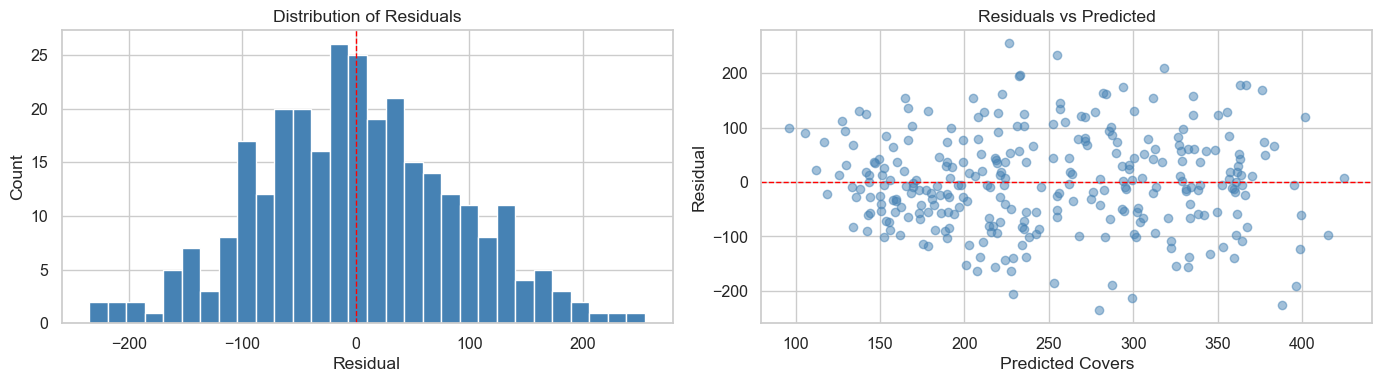

In [55]:
df['predicted_covers'] = ols.predict(sm.add_constant(df[REGRESSION_FEATURES]))
df['residual'] = df['afternoon_covers'] - df['predicted_covers']

print(f"Residual stats:")
print(df['residual'].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df['residual'], bins=30, color='steelblue', edgecolor='white')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1)
axes[0].set_xlabel('Residual')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Residuals')

axes[1].scatter(df['predicted_covers'], df['residual'], alpha=0.5, color='steelblue')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_xlabel('Predicted Covers')
axes[1].set_ylabel('Residual')
axes[1].set_title('Residuals vs Predicted')

plt.tight_layout()
plt.savefig(FIG_DIR / 'residual_analysis.png', dpi=150)
plt.show()

## 7. Synthetic Data Generation

We now use the fitted regression to generate 2000 synthetic days.

**Design decision -- row sampling over independent feature sampling**

The initial implementation sampled each feature column independently: occupancy from the occupancy distribution, temperature from the temperature distribution, and so on. This produced a KS test p-value of 0.026, rejecting the null hypothesis that real and synthetic covers share the same distribution. The cause was that independent sampling breaks the joint correlations that exist in reality: a hot day tends to be summer, summer tends to have higher occupancy, a special day tends to fall in a specific season. Sampling features independently created implausible combinations -- cold summer days, hot winter days -- that never appear in the real data. The regression, trained on realistic combinations, produced unrealistic predictions when given unrealistic inputs, and the synthetic cover distribution diverged from the real one.

The fix is to sample entire rows from the real data with replacement. Every synthetic day gets its feature values from a real observed day, so all correlations between occupancy, temperature, season, and day-of-week are preserved exactly as they occur in practice. After this change, the KS test returned p=0.408, confirming that we cannot reject the hypothesis that the two distributions are statistically equivalent.

**The generation process has four steps:**

First, we sample entire rows from the real data with replacement, taking the full feature context of a real day as-is.

Second, we pass each synthetic feature combination through the fitted regression to get a predicted cover count. This is the signal the model has learned.

Third, we add a randomly sampled residual from the 294 real residuals. Residuals are sampled independently of the features -- this is intentional. The residual represents unpredictable noise: a surprise group booking, a review posted that morning, random walk-in variation. Pairing a residual to the same row it came from would simply reproduce the original 294 observations rather than generating new ones.

Fourth, we clip any negative values to zero (covers cannot be negative) and bucket into tiers using the same thresholds computed from real data.

**Why 2000?** Two considerations drive this choice. First, we need enough examples for the model to learn reliably. With 3 classes and 6 features, tree-based models typically need several hundred examples per class minimum. 2000 days gives roughly 650 per tier if the distribution is balanced, which is comfortable. Second, we do not want to stray too far from the 294 real observations the regression was fitted on. At 2000 synthetic days, each real observation is stretched roughly 7 times -- a reasonable amplification. Generating 20000 would risk the synthetic distribution drifting away from the reality the regression captured. There has to be a balance between generating enough synthetic data for the models to learn and not digressing too far from the real data.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

N_SYNTHETIC = 2000
rng = np.random.default_rng(42)

# Sample entire rows from real data - preserves joint feature correlations
row_idx = rng.choice(len(df), size=N_SYNTHETIC, replace=True)
synthetic = df.iloc[row_idx][
    ['occupancy_%', 'temp_mean', 'day_of_week', 'is_special_day',
     'season', 'season_Summer', 'season_Winter']
].reset_index(drop=True)

# Predict covers using the fitted regression
X_synth       = synthetic[REGRESSION_FEATURES]
X_synth_const = sm.add_constant(X_synth, has_constant='add')
synthetic['predicted_covers'] = ols.predict(X_synth_const)

# Add a randomly sampled real residual (independent of features - this is the noise)
synthetic['residual']         = rng.choice(df['residual'].values, size=N_SYNTHETIC, replace=True)
synthetic['afternoon_covers'] = (synthetic['predicted_covers'] + synthetic['residual']).clip(lower=0).astype(float)

# Bucket into tiers using the same thresholds from real data
synthetic['tier'] = synthetic['afternoon_covers'].apply(to_tier)

print(f"Synthetic dataset: {len(synthetic)} days")
print(f"\nTier distribution:")
print(synthetic['tier'].value_counts().sort_index())
print(f"\nCovers stats:")
print(synthetic['afternoon_covers'].describe().round(1))

Synthetic dataset: 2000 days

Tier distribution:
tier
high      636
low       579
medium    785
Name: count, dtype: int64

Covers stats:
count    2000.0
mean      250.7
std       116.3
min         0.0
25%       168.4
50%       248.6
75%       330.5
max       615.6
Name: afternoon_covers, dtype: float64


## 8. Validation: Proving the Synthetic Distribution Matches Reality

Before training any model on the synthetic data, we must demonstrate that it is statistically consistent with the real observations. We do this two ways.

First, a visual overlay -- the real and synthetic cover distributions should have the same shape, centre, and spread.

Second, a Kolmogorov-Smirnov (KS) test -- a formal statistical test that asks whether two samples could plausibly have come from the same underlying distribution. A p-value above 0.05 means we cannot reject that hypothesis. This is the "prove the connection" step -- it gives us statistical grounds to say the synthetic data faithfully represents real demand at this property.

KS statistic : 0.0548
KS p-value   : 0.4080

Interpretation: distributions are statistically similar (p > 0.05)


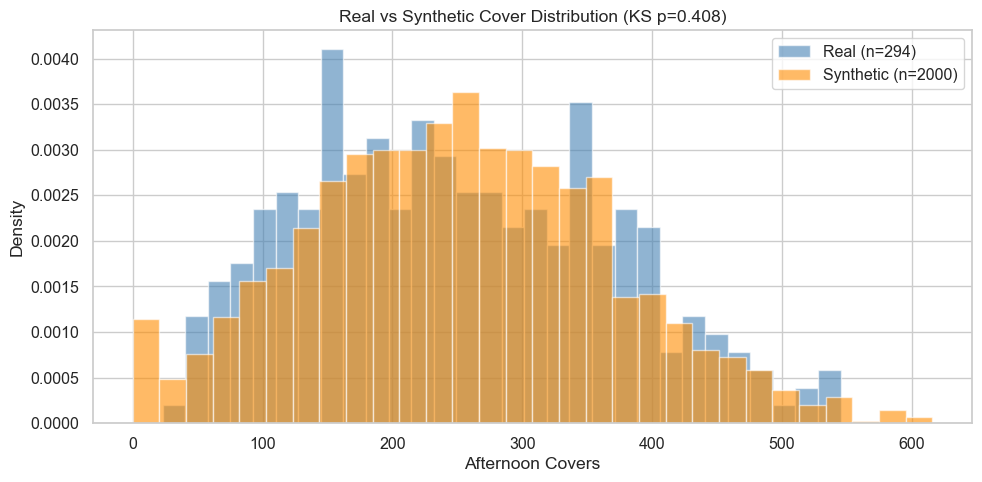

In [57]:
from scipy import stats

ks_stat, ks_pvalue = stats.ks_2samp(df['afternoon_covers'], synthetic['afternoon_covers'])
print(f"KS statistic : {ks_stat:.4f}")
print(f"KS p-value   : {ks_pvalue:.4f}")
print(f"\nInterpretation: {'distributions are statistically similar (p > 0.05)' if ks_pvalue > 0.05 else 'distributions differ significantly (p <= 0.05)'}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df['afternoon_covers'], bins=30, alpha=0.6, color='steelblue',
        label=f'Real (n={len(df)})', density=True)
ax.hist(synthetic['afternoon_covers'], bins=30, alpha=0.6, color='darkorange',
        label=f'Synthetic (n={len(synthetic)})', density=True)
ax.set_xlabel('Afternoon Covers')
ax.set_ylabel('Density')
ax.set_title(f'Real vs Synthetic Cover Distribution (KS p={ks_pvalue:.3f})')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'real_vs_synthetic_distribution.png', dpi=150)
plt.show()

## 9. Classifier Training: Synthetic Training, Real Testing

The classifier is trained entirely on synthetic data and evaluated on real held-out days. This is the critical test of the whole pipeline: if the model correctly predicts the demand tier of real days it has never seen, it demonstrates that the synthetic data generation process has successfully captured the actual demand relationships at this property.

**Test split design:** A naive chronological 80/20 split holds out the last 20% of dates, which falls entirely in January to April 2026 -- deep winter and early spring. That period contains almost no high-demand days, making it impossible to fairly evaluate the model on all three tiers. Instead we take the last 20% of each season's days separately and combine them into the test set. This gives seasonal coverage across all four quarters. Within each season we still test on the most recent observations, preserving the forward-looking nature of the evaluation.

We train a Random Forest with 200 trees and balanced class weights. The feature importances produced by this model are a direct thesis finding: they tell us empirically which signals drove the model's decisions, and should align with the regression coefficients if the pipeline has correctly captured the demand structure.

Training on : 2000 synthetic days
Testing on  : 56 real days across all seasons

Test tier distribution:
tier
high      17
low       17
medium    22
Name: count, dtype: int64

Test season distribution:
season
Summer    16
Autumn    16
Winter    16
Spring     8
Name: count, dtype: int64

--- Classification Report ---
              precision    recall  f1-score   support

        high       0.86      0.71      0.77        17
         low       0.44      0.65      0.52        17
      medium       0.47      0.36      0.41        22

    accuracy                           0.55        56
   macro avg       0.59      0.57      0.57        56
weighted avg       0.58      0.55      0.56        56



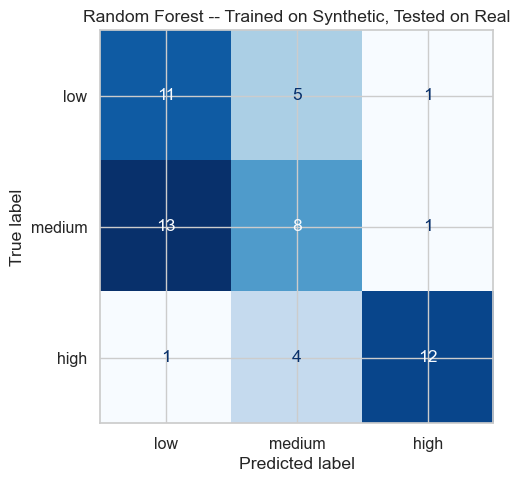

In [58]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Season-stratified split -- last 20% of each season's days, preserving time order within season
df_sorted  = df.sort_values('date').reset_index(drop=True)
test_parts = []
for season in ['Spring', 'Summer', 'Autumn', 'Winter']:
    season_days = df_sorted[df_sorted['season'] == season]
    n_test = max(1, int(len(season_days) * 0.2))
    test_parts.append(season_days.iloc[-n_test:])

df_test = pd.concat(test_parts).sort_values('date').reset_index(drop=True)

print(f"Training on : {len(synthetic)} synthetic days")
print(f"Testing on  : {len(df_test)} real days across all seasons")
print(f"\nTest tier distribution:")
print(df_test['tier'].value_counts().sort_index())
print(f"\nTest season distribution:")
print(df_test['season'].value_counts())

X_train = synthetic[REGRESSION_FEATURES]
y_train = synthetic['tier']
X_test  = df_test[REGRESSION_FEATURES]
y_test  = df_test['tier']

rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['high', 'low', 'medium']))

fig, ax = plt.subplots(figsize=(7, 5))
cm   = confusion_matrix(y_test, y_pred, labels=['low', 'medium', 'high'])
disp = ConfusionMatrixDisplay(cm, display_labels=['low', 'medium', 'high'])
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Random Forest -- Trained on Synthetic, Tested on Real')
plt.tight_layout()
plt.savefig(FIG_DIR / 'confusion_matrix_rf.png', dpi=150)
plt.show()

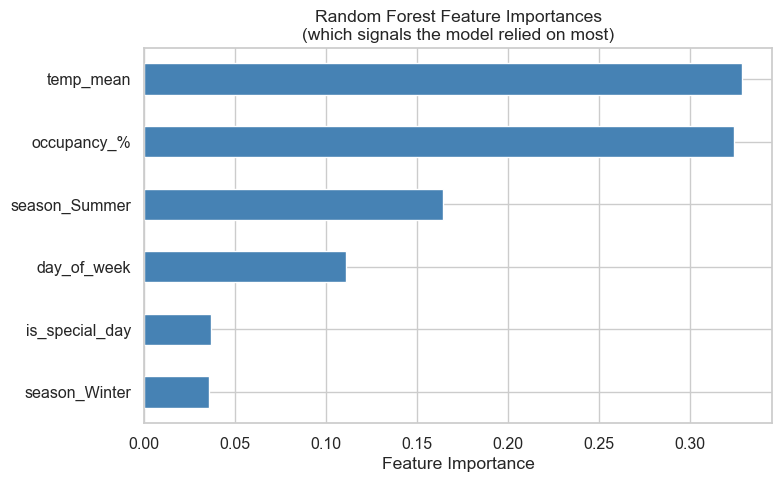

temp_mean         0.328624
occupancy_%       0.323862
season_Summer     0.164221
day_of_week       0.110737
is_special_day    0.036614
season_Winter     0.035941


In [60]:
importances = pd.Series(rf.feature_importances_, index=REGRESSION_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_xlabel('Feature Importance')
ax.set_title('Random Forest Feature Importances\n(which signals the model relied on most)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'feature_importance_rf.png', dpi=150)
plt.show()

print(importances.sort_values(ascending=False).to_string())

In [61]:
import joblib

MODEL_DIR = Path('../models')
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(rf, MODEL_DIR / 'tier_model_afternoon.pkl')
joblib.dump(REGRESSION_FEATURES, MODEL_DIR / 'tier_feature_cols_afternoon.pkl')

print("Saved to models/:")
print(f"  tier_model_afternoon.pkl")
print(f"  tier_feature_cols_afternoon.pkl")
print(f"\nFeature columns : {REGRESSION_FEATURES}")
print(f"Model           : {rf}")

Saved to models/:
  tier_model_afternoon.pkl
  tier_feature_cols_afternoon.pkl

Feature columns : ['occupancy_%', 'temp_mean', 'day_of_week', 'is_special_day', 'season_Summer', 'season_Winter']
Model           : RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)
